# 04 · EMT-TF expression (unconditional final notebook)

Categorical overlay of thresholded EMT-transcription-factor expressers on a grey manifold. Candidate panel spans Snail/Zeb/Twist **plus** the FOXC and PRRX families (per the evaluation lesson); VIM is a mesenchymal marker, **not** a TF, and is excluded. TFs are gated on detectable expression and ranked by their pseudotime association.

**Directional read (important):** in this dataset **every** detectably-expressed EMT-TF has a *negative* Spearman rho vs pseudotime — i.e. EMT-TF expression concentrates toward the pSom-high **root/origin** end of the axis, and **no EMT-TF marks the Gast/Crest terminus**. The overlay therefore shows the two most pseudotime-informative expressed factors, both **root/origin-enriched**, rather than an early↔late pair.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 2263 | pseudotime range 0.0 -> 10.9


## Rank EMT-TFs by pseudotime association (gated on detection)

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0; rho,p = spearmanr(tn, x)
    rows.append((g, round(float(expr.mean()),3), round(float(x[early].mean()),3),
                 round(float(x[late].mean()),3), round(float(rho),3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['enriched_end'] = np.where(df.mean_early >= df.mean_late, 'root/origin', 'terminus')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
det = df[df.frac_expr > 0.03].copy()
n_terminus = int((det.enriched_end == 'terminus').sum())
print(f'\ndetectably-expressed EMT-TFs (frac>3%): {list(det.TF)}')
print(f'terminus-enriched among them: {n_terminus}  -> ' +
      ('none; all EMT-TFs are root/origin-enriched (all rho_vs_t < 0)' if n_terminus==0 else 'see table'))
# pick the two most pseudotime-informative expressed factors (largest |rho|); both are root-enriched here
det['absrho'] = det.rho_vs_t.abs()
top2 = det.sort_values('absrho', ascending=False).head(2).sort_values('rho_vs_t')
tf_a, tf_b = top2.iloc[0]['TF'], top2.iloc[1]['TF']   # tf_a = strongest root association
print(f'shown pair (both root/origin-enriched): {tf_a} (strongest, {df.set_index("TF").loc[tf_a,"frac_expr"]*100:.0f}% expr, rho={df.set_index("TF").loc[tf_a,"rho_vs_t"]:+.2f})'
      f' and {tf_b} (rho={df.set_index("TF").loc[tf_b,"rho_vs_t"]:+.2f})')
EMT_TFS = f'{tf_a}, {tf_b}'

    TF  frac_expr  mean_early  mean_late  rho_vs_t enriched_end
 FOXC1      0.653       1.212      0.476    -0.415  root/origin
 SNAI2      0.142       0.313      0.100    -0.228  root/origin
 FOXC2      0.106       0.126      0.070    -0.152  root/origin
 PRRX1      0.394       0.391      0.367    -0.128  root/origin
TWIST1      0.046       0.098      0.034    -0.091  root/origin
TWIST2      0.017       0.038      0.012    -0.068  root/origin
 SNAI1      0.010       0.018      0.004    -0.062  root/origin

detectably-expressed EMT-TFs (frac>3%): ['FOXC1', 'SNAI2', 'FOXC2', 'PRRX1', 'TWIST1']
terminus-enriched among them: 0  -> none; all EMT-TFs are root/origin-enriched (all rho_vs_t < 0)
shown pair (both root/origin-enriched): FOXC1 (strongest, 65% expr, rho=-0.41) and SNAI2 (rho=-0.23)


## expression.pdf — categorical overlay of thresholded expressers

Both overlaid factors are root/origin-enriched (the axis has no terminus EMT-TF); colours distinguish the two genes, cutoffs are the upper quartile among expressers.

overlay thresholds (upper quartile among expressers): {'FOXC1': 1.58, 'SNAI2': 1.687} | cells shown: {'FOXC1': 369, 'SNAI2': 80}
FOXC1: 65.3% expressing; 369 shown, mean pseudotime = 0.44 (all = 0.51)
SNAI2: 14.2% expressing; 80 shown, mean pseudotime = 0.54 (all = 0.51)
note: both shown factors are root/origin-enriched; no EMT-TF marks the terminus in this dataset.
saved expression.pdf


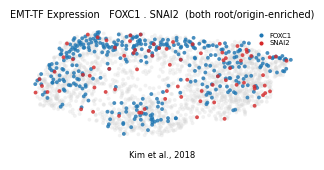

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [tf_a, tf_b]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [tf_a, tf_b]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [tf_a, tf_b]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [tf_a, tf_b]})
order = sorted([tf_a, tf_b], key=lambda g: -int(sel[g].sum()))
colors = {tf_a:'tab:blue', tf_b:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {tf_a} . {tf_b}  (both root/origin-enriched)', size=7)
# small colour key
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[tf_a],markersize=4,label=tf_a),
                   Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[tf_b],markersize=4,label=tf_b)],
          loc='upper right', frameon=False, fontsize=5, handletextpad=.2, labelspacing=.2)
ax.text(.5,-.14,'Kim et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
for g in [tf_a, tf_b]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown, mean pseudotime = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('note: both shown factors are root/origin-enriched; no EMT-TF marks the terminus in this dataset.')
print('saved expression.pdf')